# 01 数据抽样与清洗

**数据来源**：天池「淘宝用户行为」数据集（`淘宝用户行为.csv`，约 507MB，1225.7 万条原始记录）。

**字段说明**

| 字段 | 含义 |
|---|---|
| user_id | 用户 ID |
| item_id | 商品 ID |
| behavior_type | 行为类型（1=浏览 pv，2=购买 buy，3=收藏 fav，4=加购 cart） |
| user_geohash | 用户地理位置（大量缺失，本分析不使用） |
| item_category | 商品类目 ID |
| time | 行为时间（yyyy-MM-dd HH），跨度 2014-11-18 ~ 2014-12-18 |

**本 notebook 做三件事**

1. **分块读取**：507MB 文件无法（也不必要）一次性读入，采用 chunked 读取；
2. **随机抽样**：按比例从 1225.7 万条中随机抽取 **100 万条**（固定随机种子保证可复现），构建分析数据集；
3. **数据清洗与 EDA**：字段映射、时间解析、去重、缺失处理，输出日活/小时分布等基础图表。

为了方便记忆每个缩写的含义补充了完整的词汇
- pv：**Page View** 页面浏览量
- buy：**buy**（本身就是英文，业务里一般指 purchase，购买）
- fav：**Favorite** 收藏
- cart：**Cart** 购物车

补充：电商常用简写

- UV：Unique Visitor 独立访客
- CTR：Click Through Rate 点击率

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
mpl.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
print('环境就绪')

环境就绪


## 一、分块扫描原始数据

第一遍扫描：统计总行数，用于计算抽样比例。

In [31]:
RAW_FILE = '淘宝用户行为.csv'
CHUNK = 2_000_000
total_rows = 0
for ch in pd.read_csv(RAW_FILE, chunksize=CHUNK, usecols=['user_id']):
    total_rows += len(ch)
print(f'原始数据总行数：{total_rows:,}')

原始数据总行数：12,256,906


## 二、随机抽样 100 万条

第二遍扫描：每个数据块按相同比例随机抽样（`pandas.DataFrame.sample`，随机种子 28），
合并后恰好得到约 100 万条样本。分块随机抽样保证样本在时间维度上均匀分布，避免只取文件头部造成的时间偏差。

In [32]:
TARGET_N = 1_000_000
frac = TARGET_N / total_rows * 1.1   # 超抽 10%，保证收敛时样本充足
samples = []
for ch in pd.read_csv(RAW_FILE, chunksize=CHUNK, dtype=str):
    samples.append(ch.sample(frac=frac, random_state=28))
sample = pd.concat(samples, ignore_index=True)
print(f'预抽样行数：{len(sample):,}')

预抽样行数：1,100,002


In [33]:
# 收敛到精确的 100 万条
sample = sample.sample(n=TARGET_N, random_state=28).reset_index(drop=True)
sample.to_csv('data/userbehavior_1m.csv', index=False)
print(f'已保存 data/userbehavior_1m.csv，共 {len(sample):,} 条')
sample.head()

已保存 data/userbehavior_1m.csv，共 1,000,000 条


,user_id,item_id,behavior_type,user_geohash,item_category,time
0,139435539,232972408,1,NaN,6054,2014-12-16 01
1,83073587,396847325,1,99snwp1,2513,2014-12-04 20
2,96936392,364588113,1,9rnnddo,1722,2014-12-01 23
3,44909131,258706886,1,95r2u45,6513,2014-12-07 23
4,123250328,360111382,1,NaN,5027,2014-11-24 20


## 三、数据清洗

1. behavior_type 数字代码 → 行为名称；
2. time 解析为 datetime（原始粒度到小时）；
3. 剔除完全重复记录；
4. user_geohash 缺失率极高且为加密串，无分析价值，直接丢弃。

In [34]:
df = pd.read_csv('data/userbehavior_1m.csv', dtype={'user_id': str, 'item_id': str,
                                                    'item_category': str})
print('抽样数据：', df.shape)
print('\n各字段缺失值：'); print(df.isna().sum())
print('\n完全重复记录数：', df.duplicated().sum())

BEHAVIOR_MAP = {1: 'pv', 2: 'buy', 3: 'fav', 4: 'cart'}
df['behavior_type'] = pd.to_numeric(df['behavior_type']).map(BEHAVIOR_MAP)
df['time'] = pd.to_datetime(df['time'], format='%Y-%m-%d %H')
df['date'] = df['time'].dt.date
df['hour'] = df['time'].dt.hour
df = df.drop(columns=['user_geohash']).drop_duplicates()
df = df.reset_index(drop=True)
print('\n清洗后：', df.shape)
df.head()

抽样数据： (1000000, 6)

各字段缺失值：
user_id               0
item_id               0
behavior_type         0
user_geohash     680564
item_category         0
time                  0
dtype: int64

完全重复记录数： 40819

清洗后： (939270, 7)


,user_id,item_id,behavior_type,item_category,time,date,hour
0,139435539,232972408,pv,6054,2014-12-16 01:00:00,2014-12-16,1
1,83073587,396847325,pv,2513,2014-12-04 20:00:00,2014-12-04,20
2,96936392,364588113,pv,1722,2014-12-01 23:00:00,2014-12-01,23
3,44909131,258706886,pv,6513,2014-12-07 23:00:00,2014-12-07,23
4,123250328,360111382,pv,5027,2014-11-24 20:00:00,2014-11-24,20


In [35]:
print('时间范围：', df['time'].min(), '->', df['time'].max())
print('\n行为类型分布：')
dist = df['behavior_type'].value_counts()
pct = (dist / len(df) * 100).round(2)
pd.DataFrame({'行为次数': dist, '占比(%)': pct})

时间范围： 2014-11-18 00:00:00 -> 2014-12-18 23:00:00

行为类型分布：


,行为次数,占比(%)
behavior_type,,
pv,881841,93.89
fav,28095,2.99
buy,19840,2.11
cart,9494,1.01


## 四、基础 EDA

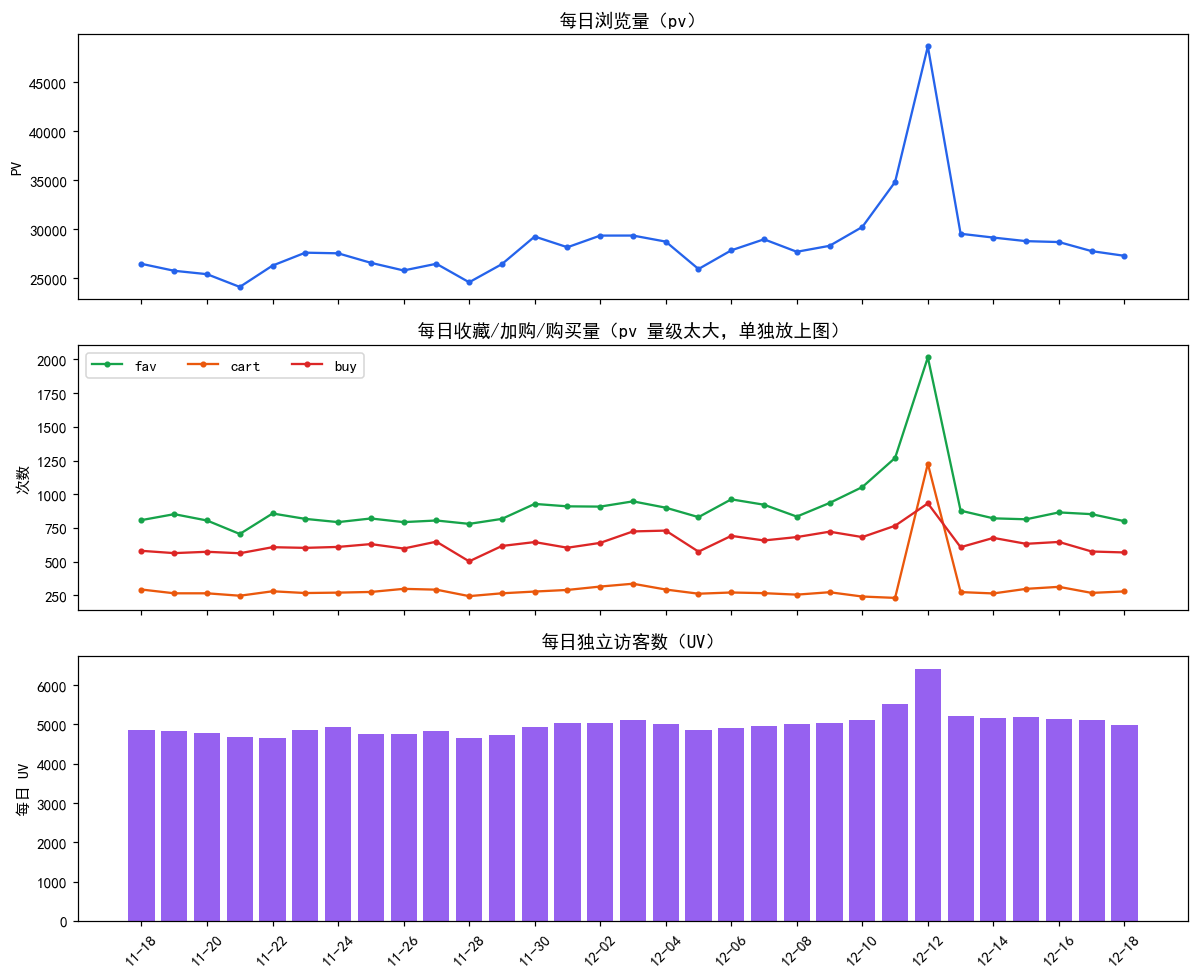

In [36]:
daily = df.groupby(['date', 'behavior_type']).size().unstack(fill_value=0)
uv_daily = df.groupby('date')['user_id'].nunique()  #计算不重复值的数量

dates = list(daily.index)
fmt_idx = list(range(0, len(dates), 2))   # x轴日期隔一个显示一个，避免挤在一起

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
# 上：pv 单画（pv 占九成量级，和收藏/加购/购买放在一起会把它们压成直线）
ax = axes[0]
ax.plot(dates, daily['pv'], marker='o', ms=3, color='#2563eb')
ax.set_ylabel('PV'); ax.set_title('每日浏览量（pv）')
# 中：收藏/加购/购买
ax = axes[1]
for col, c in zip(['fav', 'cart', 'buy'], ['#16a34a', '#ea580c', '#dc2626']):
    ax.plot(dates, daily[col], marker='o', ms=3, color=c, label=col)
ax.set_ylabel('次数'); ax.legend(ncols=3)
ax.set_title('每日收藏/加购/购买量（pv 量级太大，单独放上图）')
# 下：UV（bar直接用日期当x，和上面保持一致）
ax = axes[2]
ax.bar(dates, uv_daily.values, color='#7c3aed', alpha=.8)
ax.set_xticks([dates[i] for i in fmt_idx])                        # 先定位刻度
ax.set_xticklabels([str(dates[i])[5:] for i in fmt_idx], rotation=45)   # 再贴标签
ax.set_ylabel('每日 UV'); ax.set_title('每日独立访客数（UV）')

fig.tight_layout()
fig.savefig('figures/01_日活与行为趋势.png', dpi=150, bbox_inches='tight')
plt.show()

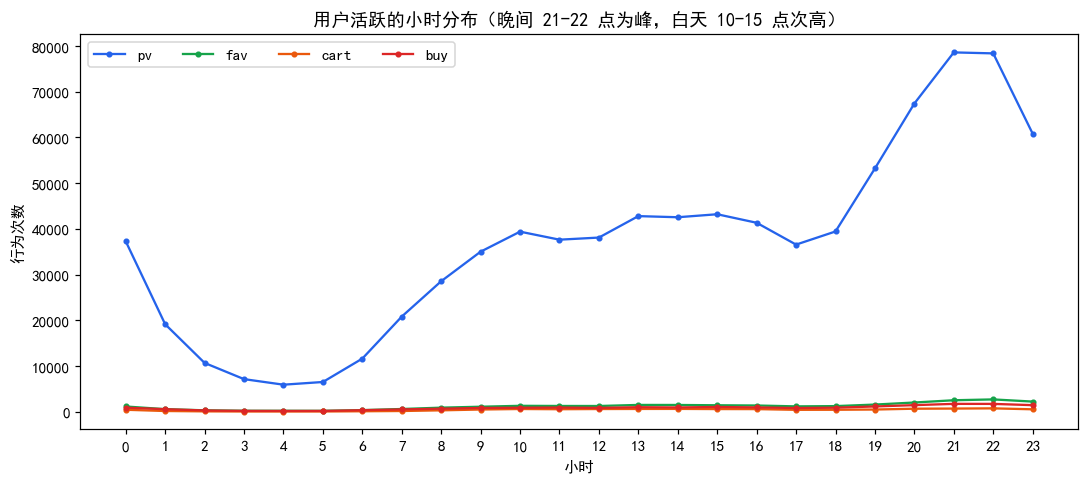

In [37]:
hourly = df.groupby(['hour', 'behavior_type']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
for col, c in zip(['pv', 'fav', 'cart', 'buy'], ['#2563eb', '#16a34a', '#ea580c', '#dc2626']):
    ax.plot(hourly.index, hourly[col], marker='o', ms=3, color=c, label=col)
ax.set_xticks(range(24)); ax.set_xlabel('小时'); ax.set_ylabel('行为次数')
ax.set_title('用户活跃的小时分布（晚间 21-22 点为峰，白天 10-15 点次高）')
ax.legend(ncols=4)
fig.tight_layout()
fig.savefig('figures/01_小时分布.png', dpi=150, bbox_inches='tight')
plt.show()

## 五、小结

- 从 **1225.7 万条**原始记录中分块随机抽样 **100 万条**（种子 28，两处抽样同种子，可复现），构建分析数据集 `data/userbehavior_1m.csv`；
- 数据时间跨度 **2014-11-18 ~ 2014-12-18**（31 天，含双 12 大促），清洗后 **93.9 万条**有效记录；
- 行为分布高度偏斜：浏览占 93.9%、购买仅 2.1%，约 **44 次浏览行为**才对应 1 次购买行为，折算到用户维度为 3,604 / 9,925 = **36.3%**（详见 02），流失发生在哪一环 → 用漏斗定位。